# Milestone 10 — Spatially Resolved Stellar Kinematic Validation

**Target:** MaNGA 8138-12704  
**DAPTYPE:** HYB10-MILESHC-MASTARSSP

## Objectives
1. Extract a major-axis stellar velocity profile using the adopted kinematic PA.
2. Compare approaching and receding sides at matched projected radii.
3. Calculate an explicitly defined aperture \(V/\sigma\).
4. Compare the kinematic PA with a photometric PA when a documented value is supplied.
5. Fit a simple projected cosine rotation model and inspect residuals.
6. Bootstrap the adopted area-weighted \(\lambda_R\) estimator.

**Important:** This notebook is an analysis template designed to run in the user's local project. It does not claim to have executed against the local FITS files. Verify all output tables and figures after running it.

## 0. Scientific conventions

- Coordinates are expressed in arcsec relative to the adopted galaxy centre.
- Position angle is measured from North through East, modulo 180 degrees.
- The major-axis coordinate is \(x' = x\sin(PA)+y\cos(PA)\), with the corresponding perpendicular coordinate \(y'=x\cos(PA)-y\sin(PA)\), assuming \(x\) increases East and \(y\) increases North.
- The major-axis profile uses a finite-width slit and reports its width explicitly.
- A cosine model is a descriptive projected model, not a full dynamical model.
- \(V/\sigma\) is defined below from the aperture-weighted second moments; do not compare it with literature values unless the same convention is used.

In [4]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

# =====================================================
# 1. AUTOMATIC PROJECT ROOT DETECTION
# =====================================================

PROJECT_NAME = "manga-stellar-kinematics"

current = Path.cwd().resolve()

# Find project root from current directory or its parents
ROOT = next(
    (
        p for p in [current, *current.parents]
        if p.name == PROJECT_NAME
    ),
    None
)

if ROOT is None:
    ROOT = Path(r"D:\KS\manga-stellar-kinematics")

if not ROOT.exists():
    raise FileNotFoundError(f"Project directory not found: {ROOT}")

# =====================================================
# 2. MAPS FILE
# =====================================================

FILENAME = "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz"

MAPS_PATH = ROOT / "data" / "raw" / FILENAME

if not MAPS_PATH.exists():
    matches = list(ROOT.rglob(FILENAME))

    if matches:
        MAPS_PATH = matches[0]
    else:
        raise FileNotFoundError(
            f"MAPS file not found: {FILENAME}\n"
            f"Project root: {ROOT}\n"
            "Check whether the FITS file has been downloaded."
        )

# =====================================================
# 3. OUTPUT DIRECTORIES
# =====================================================

OUT = ROOT / "outputs"
FIG = OUT / "figures"
REP = OUT / "reports"

FIG.mkdir(parents=True, exist_ok=True)
REP.mkdir(parents=True, exist_ok=True)

# =====================================================
# 4. DISPLAY CONFIGURATION
# =====================================================

print("=" * 60)
print("MANGA STELLAR KINEMATICS PROJECT")
print("=" * 60)

print(f"Current directory : {current}")
print(f"Project root      : {ROOT}")
print(f"MAPS file         : {MAPS_PATH}")
print(f"Output directory  : {OUT}")
print(f"Figures directory : {FIG}")
print(f"Reports directory : {REP}")

print("\nFile size:", round(MAPS_PATH.stat().st_size / (1024**2), 2), "MB")
print("\nSTATUS: All paths configured successfully.")


MANGA STELLAR KINEMATICS PROJECT
Current directory : D:\KS\manga-stellar-kinematics\notebooks
Project root      : D:\KS\manga-stellar-kinematics
MAPS file         : D:\KS\manga-stellar-kinematics\data\raw\manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz
Output directory  : D:\KS\manga-stellar-kinematics\outputs
Figures directory : D:\KS\manga-stellar-kinematics\outputs\figures
Reports directory : D:\KS\manga-stellar-kinematics\outputs\reports

File size: 10.49 MB

STATUS: All paths configured successfully.


## 1. Load the MAPS products and inspect required extensions

In [5]:
with fits.open(MAPS_PATH, memmap=True) as hdul:
    names = [h.name.upper() for h in hdul]
    print("Available HDUs:", names)

    def get_data(name):
        idx = names.index(name.upper())
        return np.asarray(hdul[idx].data).copy(), hdul[idx].header.copy()

    BINID, binid_hdr = get_data("BINID")
    VEL, vel_hdr = get_data("STELLAR_VEL")
    VEL_IVAR, _ = get_data("STELLAR_VEL_IVAR")
    VEL_MASK, _ = get_data("STELLAR_VEL_MASK")
    SIGMA, sig_hdr = get_data("STELLAR_SIGMA")
    SIGMA_IVAR, _ = get_data("STELLAR_SIGMA_IVAR")
    SIGMA_MASK, _ = get_data("STELLAR_SIGMA_MASK")
    SIGMACORR, _ = get_data("STELLAR_SIGMACORR")
    BIN_MFLUX, _ = get_data("BIN_MFLUX")
    BIN_AREA, _ = get_data("BIN_AREA")
    BIN_LWELLCOO, _ = get_data("BIN_LWELLCOO")

print("BINID:", BINID.shape, "VEL:", VEL.shape, "SIGMA:", SIGMA.shape)
print("BIN_LWELLCOO:", BIN_LWELLCOO.shape)

Available HDUs: ['PRIMARY', 'SPX_SKYCOO', 'SPX_ELLCOO', 'SPX_MFLUX', 'SPX_MFLUX_IVAR', 'SPX_SNR', 'BINID', 'BIN_LWSKYCOO', 'BIN_LWELLCOO', 'BIN_AREA', 'BIN_FAREA', 'BIN_MFLUX', 'BIN_MFLUX_IVAR', 'BIN_MFLUX_MASK', 'BIN_SNR', 'STELLAR_VEL', 'STELLAR_VEL_IVAR', 'STELLAR_VEL_MASK', 'STELLAR_SIGMA', 'STELLAR_SIGMA_IVAR', 'STELLAR_SIGMA_MASK', 'STELLAR_SIGMACORR', 'STELLAR_FOM', 'EMLINE_SFLUX', 'EMLINE_SFLUX_IVAR', 'EMLINE_SFLUX_MASK', 'EMLINE_SEW', 'EMLINE_SEW_CNT', 'EMLINE_SEW_IVAR', 'EMLINE_SEW_MASK', 'EMLINE_GFLUX', 'EMLINE_GFLUX_IVAR', 'EMLINE_GFLUX_MASK', 'EMLINE_GEW', 'EMLINE_GEW_CNT', 'EMLINE_GEW_IVAR', 'EMLINE_GEW_MASK', 'EMLINE_GVEL', 'EMLINE_GVEL_IVAR', 'EMLINE_GVEL_MASK', 'EMLINE_GSIGMA', 'EMLINE_GSIGMA_IVAR', 'EMLINE_GSIGMA_MASK', 'EMLINE_INSTSIGMA', 'EMLINE_TPLSIGMA', 'EMLINE_GA', 'EMLINE_GANR', 'EMLINE_FOM', 'EMLINE_LFOM', 'SPECINDEX', 'SPECINDEX_IVAR', 'SPECINDEX_MASK', 'SPECINDEX_CORR', 'SPECINDEX_MODEL', 'SPECINDEX_BF', 'SPECINDEX_BF_IVAR', 'SPECINDEX_BF_MASK', 'SPECINDEX_B

## 2. Define the stellar footprint and collapse to one record per bin

In [6]:
# C2 = stellar continua; NumPy plane index 1 for this MAPS product.
stellar_binid = BINID[1] if BINID.ndim == 3 else BINID
footprint = stellar_binid >= 0

# BIN_LWELLCOO channels: R [arcsec], R/Re, theta [deg].
# Confirm channel labels in the FITS header before interpreting coordinates.
print("BIN_LWELLCOO header:")
for key in ("C1", "C2", "C3"):
    if key in binid_hdr:
        print(key, binid_hdr[key])

# Coordinates are expected as (3, ny, nx): radius, radius/Re, theta.
if BIN_LWELLCOO.ndim != 3 or BIN_LWELLCOO.shape[0] < 3:
    raise ValueError("Unexpected BIN_LWELLCOO shape; inspect the DAP data model.")

R_ARCSEC = BIN_LWELLCOO[0].astype(float)
R_RE = BIN_LWELLCOO[1].astype(float)
THETA_DEG = BIN_LWELLCOO[2].astype(float)

# Correct instrumental broadening using channel 0 of STELLAR_SIGMACORR.
sigmacorr = SIGMACORR[0] if SIGMACORR.ndim == 3 else SIGMACORR
radicand = SIGMA.astype(float)**2 - sigmacorr.astype(float)**2
SIGMA_CORR = np.sqrt(np.clip(radicand, 0, None))

# Basic quality selection: covered stellar bins, finite quantities, positive IVAR,
# and zero DAP mask. This reproduces the strict in-footprint selection.
valid_spax = (
    footprint
    & np.isfinite(VEL) & np.isfinite(SIGMA_CORR)
    & (VEL_IVAR > 0) & (SIGMA_IVAR > 0)
    & (VEL_MASK == 0) & (SIGMA_MASK == 0)
    & np.isfinite(R_ARCSEC) & np.isfinite(R_RE)
)

rows = []
for bid in np.unique(stellar_binid[valid_spax]):
    yy, xx = np.where(valid_spax & (stellar_binid == bid))
    if len(yy) == 0:
        continue
    y, x = yy[0], xx[0]  # one representative DAP bin measurement
    rows.append({
        "binid": int(bid),
        "n_spaxels": int(len(yy)),
        "x_pix": int(x), "y_pix": int(y),
        "vel": float(VEL[y, x]),
        "sigma": float(SIGMA_CORR[y, x]),
        "vel_ivar": float(VEL_IVAR[y, x]),
        "sigma_ivar": float(SIGMA_IVAR[y, x]),
        "r_arcsec": float(R_ARCSEC[y, x]),
        "r_re": float(R_RE[y, x]),
        "theta_deg": float(THETA_DEG[y, x]),
        "bin_area": float(BIN_AREA[y, x]) if np.isfinite(BIN_AREA[y, x]) else float(len(yy)),
        "bin_mflux": float(BIN_MFLUX[y, x]),
    })

df = pd.DataFrame(rows)
print("Valid unique bins:", len(df))
print("Covered valid spaxels:", int(valid_spax.sum()))
display(df.head())

BIN_LWELLCOO header:
C1 Binned spectra
C2 Stellar continua
C3 Em. line moments
Valid unique bins: 2194
Covered valid spaxels: 2704


,binid,n_spaxels,x_pix,y_pix,vel,sigma,vel_ivar,sigma_ivar,r_arcsec,r_re,theta_deg,bin_area,bin_mflux
0,0,1,36,35,45.594540,200.855285,0.848015,0.794889,0.516013,0.047491,0.222567,0.25,3.394803
1,1,1,35,35,48.128662,200.283323,0.635181,0.599168,0.813662,0.074886,0.350949,0.25,3.106903
2,2,1,35,34,71.922836,192.368593,0.629472,0.574284,1.152312,0.106053,0.497016,0.25,2.567872
3,3,1,36,34,67.358833,197.203099,0.679026,0.628848,1.033644,0.095132,0.445832,0.25,2.901470
4,4,1,34,34,75.000656,191.777131,0.507001,0.464112,1.612765,0.148431,0.695619,0.25,2.118967


## 3. Set the adopted kinematic PA and construct major/minor-axis coordinates

In [7]:
KIN_PA_DEG = 167.300313  # Milestone 9 inverse-variance plane-fit PA
SLIT_HALF_WIDTH_ARCSEC = 2.0  # EDIT after checking PSF and spatial sampling
SYSTEMIC_VEL = 33.644056  # descriptive reference median from Milestone 9

# Use the DAP light-weighted polar angle to build a consistent projected coordinate.
# Convert theta to x-East/y-North under the convention documented above.
theta = np.deg2rad(df["theta_deg"].to_numpy())
r = df["r_arcsec"].to_numpy()
x_east = r * np.sin(theta)
y_north = r * np.cos(theta)

pa = np.deg2rad(KIN_PA_DEG)
df["major_arcsec"] = x_east*np.sin(pa) + y_north*np.cos(pa)
df["minor_arcsec"] = x_east*np.cos(pa) - y_north*np.sin(pa)
df["v_resid"] = df["vel"] - SYSTEMIC_VEL

print(df[["major_arcsec", "minor_arcsec", "v_resid"]].describe())

       major_arcsec  minor_arcsec       v_resid
count   2194.000000   2194.000000  2.194000e+03
mean     -10.198376     -3.302436 -3.917222e+00
std        3.660400      1.430964  1.393544e+02
min      -19.079028     -7.533577 -2.413584e+02
25%      -13.068540     -4.410435 -1.305915e+02
50%      -10.712265     -3.386929  3.201904e-07
75%       -7.623002     -2.203474  1.252330e+02
max       -0.017344     -0.003911  2.200158e+02


## 4. Major-axis velocity profile

,r_mid_arcsec,n_bins,median_v_approach,median_v_recede,median_sigma
0,0.2910,3,-7.623651,NaN,201.590721
1,0.8745,10,-7.347584,NaN,200.332910
2,1.4575,14,-8.653495,NaN,196.218326
3,2.0405,25,-19.900540,NaN,186.036509
4,2.6235,26,0.697349,NaN,175.047455
5,3.2065,34,-25.717117,NaN,165.042683
6,3.7895,43,-14.541887,NaN,152.115967
7,4.3725,45,0.129729,NaN,141.998766
8,4.9555,55,-11.057047,NaN,133.787229
9,5.5385,60,-10.026848,NaN,128.304128


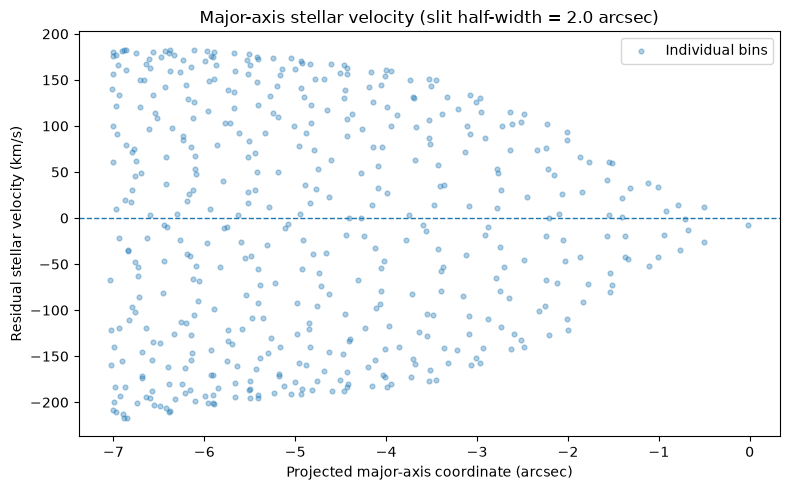

In [8]:
slit = df[np.abs(df["minor_arcsec"]) <= SLIT_HALF_WIDTH_ARCSEC].copy()
slit["side"] = np.where(slit["major_arcsec"] >= 0, "receding-side candidate", "approaching-side candidate")
slit["r_major"] = np.abs(slit["major_arcsec"])

# Radial bins in projected major-axis distance.
MAX_R = float(slit["r_major"].quantile(0.98))
N_RADIAL_BINS = 12
edges = np.linspace(0, MAX_R, N_RADIAL_BINS + 1)
slit["radial_bin"] = pd.cut(slit["r_major"], edges, include_lowest=True)

profile_rows = []
for interval, grp in slit.groupby("radial_bin", observed=False):
    if len(grp) == 0:
        continue
    profile_rows.append({
        "r_mid_arcsec": 0.5*(interval.left + interval.right),
        "n_bins": len(grp),
        "median_v_approach": grp.loc[grp.major_arcsec < 0, "v_resid"].median(),
        "median_v_recede": grp.loc[grp.major_arcsec >= 0, "v_resid"].median(),
        "median_sigma": grp["sigma"].median(),
    })
major_profile = pd.DataFrame(profile_rows)
display(major_profile)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(slit["major_arcsec"], slit["v_resid"], s=12, alpha=0.35, label="Individual bins")
ax.axhline(0, ls="--", lw=1)
ax.set(xlabel="Projected major-axis coordinate (arcsec)", ylabel="Residual stellar velocity (km/s)",
       title=f"Major-axis stellar velocity (slit half-width = {SLIT_HALF_WIDTH_ARCSEC:.1f} arcsec)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "milestone10_major_axis_velocity.png", dpi=180)
plt.show()

## 5. Approaching/receding-side symmetry

,r_mid_arcsec,n_bins,median_v_approach,median_v_recede,median_sigma


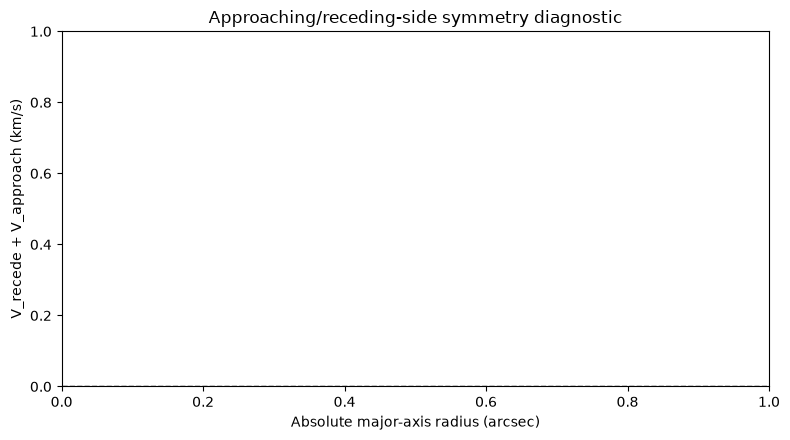

In [9]:
# Compare absolute velocities at matched |major-axis radius|.
sym = major_profile.dropna(subset=["median_v_approach", "median_v_recede"]).copy()
if len(sym):
    sym["side_difference_km_s"] = sym["median_v_recede"] + sym["median_v_approach"]
    sym["side_amplitude_ratio"] = (
        np.abs(sym["median_v_recede"]) /
        np.maximum(np.abs(sym["median_v_approach"]), 1e-8)
    )
display(sym)

fig, ax = plt.subplots(figsize=(8, 4.5))
if len(sym):
    ax.plot(sym["r_mid_arcsec"], sym["side_difference_km_s"], marker="o")
ax.axhline(0, color="black", ls="--", lw=1)
ax.set(xlabel="Absolute major-axis radius (arcsec)",
       ylabel="V_recede + V_approach (km/s)",
       title="Approaching/receding-side symmetry diagnostic")
fig.tight_layout()
fig.savefig(FIG / "milestone10_side_symmetry.png", dpi=180)
plt.show()

## 6. Simple projected cosine rotation model

In [10]:
# Descriptive model: v_resid = A * cos(phi) * f(R), with a simple arctan-like
# radial rise. This is a diagnostic parameterization, not a dynamical fit.
from scipy.optimize import curve_fit

def projected_rotation_model(coords, vmax, rt):
    major, minor = coords
    radius = np.hypot(major, minor)
    cos_phi = np.divide(major, radius, out=np.zeros_like(major), where=radius > 0)
    return vmax * (2/np.pi) * np.arctan(radius / np.maximum(rt, 1e-3)) * cos_phi

fit_df = df[np.isfinite(df["v_resid"])].copy()
p0 = [200.0, max(np.nanmedian(fit_df["r_arcsec"]), 0.5)]
try:
    popt, pcov = curve_fit(
        projected_rotation_model,
        (fit_df["major_arcsec"].to_numpy(), fit_df["minor_arcsec"].to_numpy()),
        fit_df["v_resid"].to_numpy(),
        p0=p0, bounds=([0.0, 0.05], [600.0, 30.0]), maxfev=20000
    )
    fit_df["model_vel"] = projected_rotation_model(
        (fit_df["major_arcsec"].to_numpy(), fit_df["minor_arcsec"].to_numpy()), *popt
    )
    fit_df["model_residual"] = fit_df["v_resid"] - fit_df["model_vel"]
    print(f"Descriptive Vmax parameter: {popt[0]:.2f} km/s")
    print(f"Descriptive turnover radius: {popt[1]:.2f} arcsec")
    print(f"Residual RMS: {np.sqrt(np.mean(fit_df.model_residual**2)):.2f} km/s")
except Exception as exc:
    warnings.warn(f"Cosine model fit failed: {exc}")

Descriptive Vmax parameter: 4.17 km/s
Descriptive turnover radius: 0.05 arcsec
Residual RMS: 139.32 km/s


## 7. Aperture V/sigma with explicit weighting

In [11]:
# Within Re and 2Re, calculate luminosity-weighted V/sigma:
# (i) sqrt(<V^2>_F / <sigma^2>_F), where V is residual velocity.
# This is one stated convention, not the only convention in the literature.
def aperture_v_over_sigma(data, rlim, use_area=True):
    g = data[data.r_re <= rlim].copy()
    if use_area:
        w = g.bin_mflux.to_numpy() * g.bin_area.to_numpy()
    else:
        w = g.bin_mflux.to_numpy()
    good = np.isfinite(w) & (w > 0) & np.isfinite(g.v_resid) & np.isfinite(g.sigma)
    g, w = g.loc[good], w[good]
    if len(g) == 0:
        return np.nan, 0
    v2 = np.average(g.v_resid.to_numpy()**2, weights=w)
    s2 = np.average(g.sigma.to_numpy()**2, weights=w)
    return np.sqrt(v2/s2), len(g)

vs_rows = []
for aperture in (1.0, 2.0):
    for area_weight in (False, True):
        val, n = aperture_v_over_sigma(df, aperture, use_area=area_weight)
        vs_rows.append({"aperture_Re": aperture,
                        "weighting": "BIN_MFLUX x BIN_AREA" if area_weight else "BIN_MFLUX per bin",
                        "V_over_sigma": val, "n_bins": n})
vs_table = pd.DataFrame(vs_rows)
display(vs_table)
vs_table.to_csv(REP / "milestone10_v_over_sigma.csv", index=False)

,aperture_Re,weighting,V_over_sigma,n_bins
0,1.0,BIN_MFLUX per bin,0.793865,1024
1,1.0,BIN_MFLUX x BIN_AREA,0.793865,1024
2,2.0,BIN_MFLUX per bin,0.936015,2194
3,2.0,BIN_MFLUX x BIN_AREA,0.931989,2194


## 8. Photometric versus kinematic PA

A photometric PA must come from a documented imaging fit or catalogue measurement for this same target. Do not guess it from the velocity map.

Enter the value and its source below. If unknown, leave `None`; the notebook will report that the comparison is pending.

In [12]:
PHOTOMETRIC_PA_DEG = None  # e.g. set a documented value in degrees
PHOTOMETRIC_PA_SOURCE = None  # e.g. catalogue/paper name and identifier

def pa_difference_180(pa1, pa2):
    return abs((pa1 - pa2 + 90) % 180 - 90)

if PHOTOMETRIC_PA_DEG is None:
    print("Photometric PA comparison pending: no sourced photometric PA supplied.")
else:
    delta = pa_difference_180(KIN_PA_DEG, PHOTOMETRIC_PA_DEG)
    print(f"Kinematic PA: {KIN_PA_DEG:.2f} deg")
    print(f"Photometric PA: {PHOTOMETRIC_PA_DEG:.2f} deg")
    print(f"Misalignment angle (0–90 deg): {delta:.2f} deg")
    print("Photometric PA source:", PHOTOMETRIC_PA_SOURCE)

Photometric PA comparison pending: no sourced photometric PA supplied.


## 9. Bootstrap the area-weighted λR estimator

In [13]:
# Recompute the same area-weighted estimator under bin-level bootstrap resampling.
# Uses the projected radius and velocity residuals already in the bin table.
def lambda_r(data):
    w = data["bin_mflux"].to_numpy() * data["bin_area"].to_numpy()
    R = data["r_arcsec"].to_numpy()
    V = data["v_resid"].to_numpy()
    S = data["sigma"].to_numpy()
    good = np.isfinite(w) & (w > 0) & np.isfinite(R) & (R >= 0) & np.isfinite(V) & np.isfinite(S)
    if good.sum() == 0:
        return np.nan
    w, R, V, S = w[good], R[good], V[good], S[good]
    numerator = np.sum(w * R * np.abs(V))
    denominator = np.sum(w * R * np.sqrt(V**2 + S**2))
    return numerator / denominator if denominator > 0 else np.nan

rng = np.random.default_rng(20261105)
N_BOOT = 2000
boot_rows = []
for aperture in (1.0, 2.0):
    sub = df[df.r_re <= aperture].reset_index(drop=True)
    vals = []
    if len(sub) < 2:
        warnings.warn(f"Too few bins for bootstrap within {aperture} Re")
        continue
    for _ in range(N_BOOT):
        sample_idx = rng.integers(0, len(sub), len(sub))
        vals.append(lambda_r(sub.iloc[sample_idx]))
    vals = np.asarray(vals)
    boot_rows.append({
        "aperture_Re": aperture,
        "lambdaR_area_weighted": lambda_r(sub),
        "p16": np.nanpercentile(vals, 16),
        "median": np.nanpercentile(vals, 50),
        "p84": np.nanpercentile(vals, 84),
        "n_bins": len(sub),
    })
lambda_boot = pd.DataFrame(boot_rows)
display(lambda_boot)
lambda_boot.to_csv(REP / "milestone10_lambdaR_area_weighted_bootstrap.csv", index=False)

,aperture_Re,lambdaR_area_weighted,p16,median,p84,n_bins
0,1.0,0.646215,0.637837,0.646270,0.654439,1024
1,2.0,0.699775,0.693605,0.699588,0.706100,2194


## 10. Export profiles and model diagnostics

In [14]:
major_profile.to_csv(REP / "milestone10_major_axis_profile.csv", index=False)
if "fit_df" in globals() and "model_residual" in fit_df:
    fit_df.to_csv(REP / "milestone10_projected_rotation_model_residuals.csv", index=False)

summary = [
    "Milestone 10 — Spatially Resolved Kinematic Validation",
    f"Target: MaNGA 8138-12704",
    f"Valid unique stellar bins: {len(df)}",
    f"Adopted kinematic PA: {KIN_PA_DEG:.4f} deg",
    f"Major-axis slit half-width: {SLIT_HALF_WIDTH_ARCSEC:.3f} arcsec",
    f"Systemic/reference velocity subtracted: {SYSTEMIC_VEL:.4f} km/s",
    "V/sigma definition: sqrt(<V_resid^2>_F / <sigma^2>_F), with F=BIN_MFLUX*BIN_AREA",
]
if PHOTOMETRIC_PA_DEG is not None:
    summary.append(f"Photometric PA: {PHOTOMETRIC_PA_DEG} deg ({PHOTOMETRIC_PA_SOURCE})")
(REP / "milestone10_summary.txt").write_text("\n".join(summary), encoding="utf-8")
print("\n".join(summary))
print("Saved outputs to:", REP)

Milestone 10 — Spatially Resolved Kinematic Validation
Target: MaNGA 8138-12704
Valid unique stellar bins: 2194
Adopted kinematic PA: 167.3003 deg
Major-axis slit half-width: 2.000 arcsec
Systemic/reference velocity subtracted: 33.6441 km/s
V/sigma definition: sqrt(<V_resid^2>_F / <sigma^2>_F), with F=BIN_MFLUX*BIN_AREA
Saved outputs to: D:\KS\manga-stellar-kinematics\outputs\reports


## 11. Interpretation checklist

Before making a scientific claim, check:

- [ ] The adopted centre and the DAP `BIN_LWELLCOO` angle convention are confirmed.
- [ ] The slit width is justified relative to the PSF and spatial sampling.
- [ ] Both sides have adequate radial coverage and bin counts.
- [ ] The photometric PA is sourced from imaging/catalogue data before discussing misalignment.
- [ ] The cosine model is described as phenomenological, not a full dynamical model.
- [ ] \(V/\sigma\) definition and flux weighting are stated whenever reported.
- [ ] The new area-weighted \(\lambda_R\) bootstrap is compared with the point estimate and not mixed with the earlier per-bin bootstrap.
- [ ] Systematics (PSF, inclination, template mismatch, DAP assumptions) are discussed.

**Scientific boundary:** these measurements can characterize projected stellar kinematics. They cannot, alone, establish a supermassive-black-hole binary.